# Hebben planeten uit groep 1 andere gasreuzen als buren?

## Kort antwoord
**Ja. In onze NASA-momentopname hebben 22 van de 579 sterren met een planeet uit de huidige PCA-SOM-groep 1 nog een bekende gasreusachtige planeet.** Dat is 3,8% van deze geselecteerde sterren. Vier verdere sterren hebben een zeer zware begeleider die we afzonderlijk tellen. Bij 552 sterren is in deze tabel geen andere bevestigde, onbetwiste planeet opgenomen.

Dit is een telling van **bekende** planeten, geen schatting van het werkelijke aandeel stelsels met zulke buren. De ontdekking van buitenplaneten hangt sterk af van meetmethode, waarnemingsduur en gerichte vervolgmetingen. De waarnemingsdekking is niet voor alle sterren gelijk.

## Context en methode
We veranderen geen enkele SOM-groep. De bestaande groep 1 bevat 580 planeten bij 579 verschillende NASA-hostnamen. Bij iedere groep-1-planeet zoeken we alle andere planeten met **dezelfde hostnaam**, ook als die onvoldoende gegevens hadden om aan de SOM mee te doen. Twee groep-1-planeten kunnen elkaars buur zijn; DMPP-2 is zo'n geval. Sterren tellen we slechts eenmaal.

De bron is de volledige PSCompPars-momentopname van 18 oktober 2026 Nederlandse tijd (17 oktober 23:36 UTC), met 6.451 planeten vóór analysefilters. Alleen `pl_controv_flag=0` telt mee voor de bekende begeleiders. Een afzonderlijk benoemde begeleidende ster in een dubbelster wordt niet automatisch met de gastster samengevoegd.

### Wat noemen we hier een gasreusachtige planeet?
Dit is een praktische selectie, geen rechtstreeks vastgestelde samenstelling:

- Niet uit de massa-straalrelatie ingevulde massa of minimum-massa **vanaf 50 aardmassa's**, óf een niet-ingevulde straal **vanaf 8 aardstralen**.
- Een ondergrens boven de drempel mag meetellen; een bovengrens is niet voldoende. Daardoor wordt WASP-47 c terecht meegenomen, ook al is zijn massa als ondergrens vastgelegd.
- Begeleiders met een bekende massa of minimum-massa **vanaf 13 Jupitermassa's** worden apart gehouden. Dat is een operationele grens en geen sluitend onderscheid naar ontstaansgeschiedenis. Een minimum-massa onder die grens sluit een hogere werkelijke massa niet uit.
- Door NASA ingevulde stralen of massa's dienen niet als zelfstandig bewijs voor deze selectie.

Als we de massadrempel variëren van 30 tot 100 aardmassa's, met dezelfde alternatieve straalgrens, blijft het aantal gevonden sterren 22. Sommige individuele begeleiders wisselen daarbij wel van categorie.

## Opnieuw uitvoeren
Pak de volledige map uit, installeer zo nodig `pip install -r requirements.txt` en open dit notebook in `modern_som`. Er wordt geen nieuwe indeling gemaakt en geen nieuwe download gedaan.

In [1]:
import contextlib,io,json
import pandas as pd
from IPython.display import display,Markdown,Image
from analysis import ROOT
import group1_companions
with contextlib.redirect_stdout(io.StringIO()):
    result=group1_companions.analyze()
out=ROOT/'results_group1_companions'
assert result['host_stars']==579 and result['hosts_with_extra_giant_proxy']==22
display(pd.DataFrame({'Categorie':['Met andere gasreusachtige planeet','Geen dergelijke reus, wel zeer zware begeleider','Alleen kleinere andere planeten bekend','Geen andere planeet bekend'],'Aantal sterren':[result['hosts_with_extra_giant_proxy'],result['hosts_with_only_heavy_not_extra_giant'],result['hosts_with_neither_extra_giant_nor_heavy_but_other_planets'],result['hosts_no_other_planets_known']]}))

,Categorie,Aantal sterren
0,Met andere gasreusachtige planeet,22
1,"Geen dergelijke reus, wel zeer zware begeleider",4
2,Alleen kleinere andere planeten bekend,1
3,Geen andere planeet bekend,552


## Overzicht
De categorieën hieronder overlappen niet. Eén van de 22 stelsels met een extra gasreusachtige planeet (upsilon Andromedae) heeft daarnaast ook een zeer zware begeleider; die ster staat in de eerste categorie.

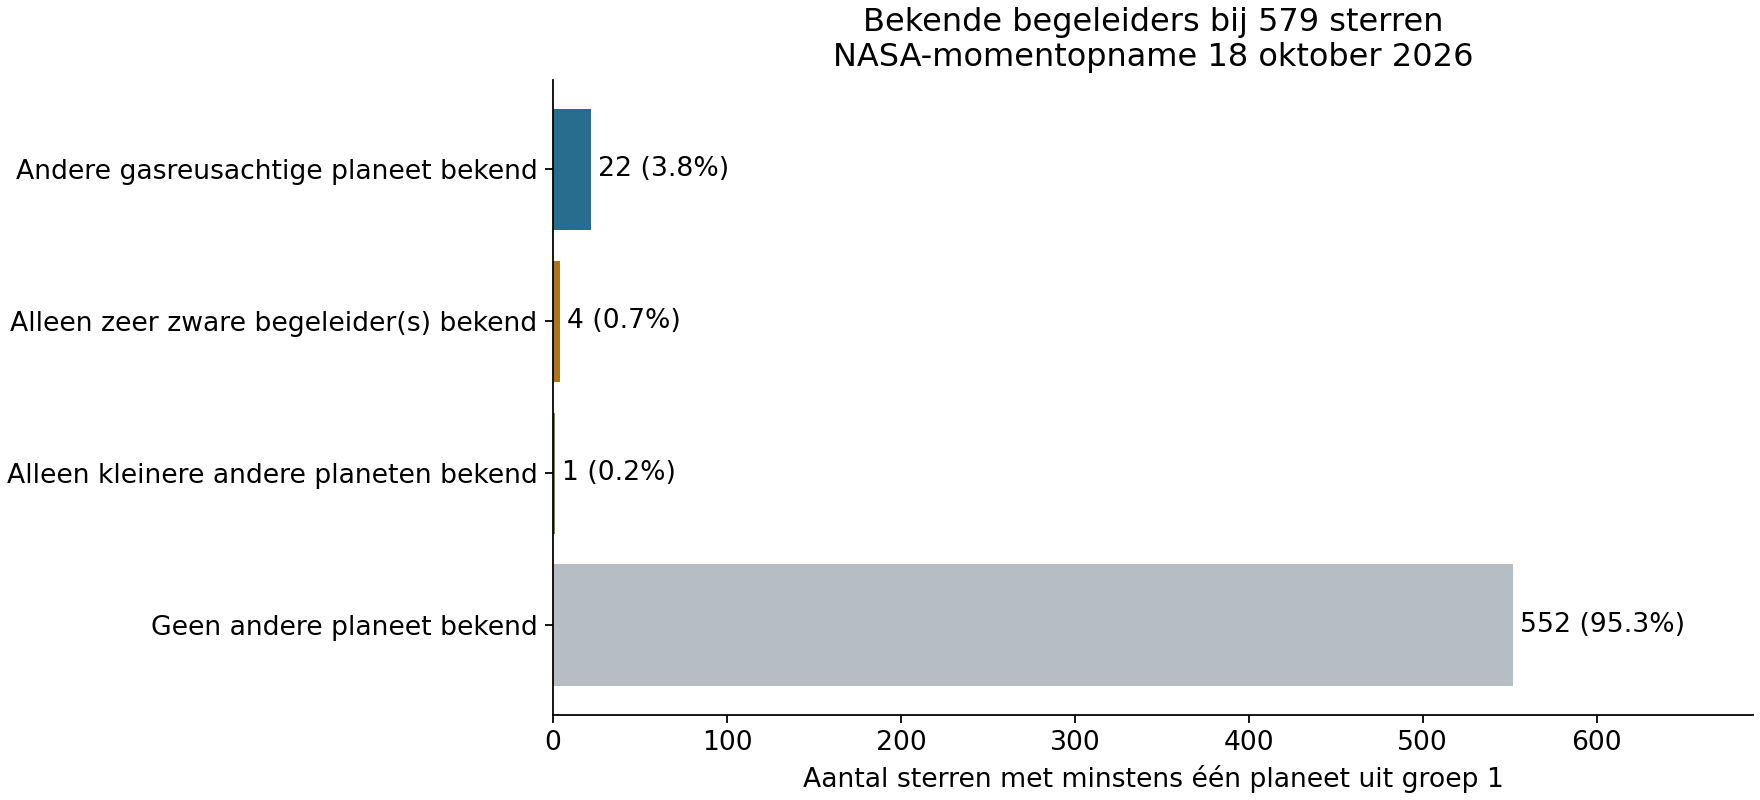

In [2]:
display(Image(filename=str(out/'begeleiders_overzicht.png')))

## Alle 22 gevonden sterren
De tabel toont welke groep-1-planeet de aanleiding vormde om de ster te onderzoeken en welke andere reusachtige planeten bekend zijn. Een planeet kan zowel in de eerste als tweede kolom voorkomen wanneer twee groep-1-planeten elkaars buur zijn. Dit wordt niet dubbel als ster geteld.

In [3]:
hosts=pd.read_csv(out/'telling_per_ster.csv').fillna('')
display(hosts.loc[hosts.andere_reus_bekend,['ster','groep1_planeten','andere_reuzen','aantal_bekende_planeten']].reset_index(drop=True))

,ster,groep1_planeten,andere_reuzen,aantal_bekende_planeten
0,DMPP-2,DMPP-2 b; DMPP-2 c,DMPP-2 b; DMPP-2 c; DMPP-2 d,3
1,HAT-P-2,HAT-P-2 b,HAT-P-2 c,2
2,HATS-59,HATS-59 b,HATS-59 c,2
3,HD 118203,HD 118203 b,HD 118203 c,2
4,HD 13908,HD 13908 b,HD 13908 c,2
5,HD 187123,HD 187123 b,HD 187123 c,2
6,HD 217107,HD 217107 b,HD 217107 c,2
7,HD 38529,HD 38529 b,HD 38529 c,2
8,HD 83443,HD 83443 b,HD 83443 c,2
9,HIP 14810,HIP 14810 b,HIP 14810 c; HIP 14810 d,3


## Voorbeelden: binnenplaneet en buitenplaneet
Deze omlooptijden komen uit de bewaarde samengestelde NASA-tabel. Afzonderlijke publicaties kunnen andere schattingen geven. Een omlooptijd van een verre planeet is niet altijd even nauwkeurig bepaald.

| Ster | Planeet uit groep 1 | Omlooptijd | Andere gasreusachtige planeet(en) | Omlooptijd(en) |
|---|---|---:|---|---:|
| WASP-47 | b | 4,16 dagen | c | 589,57 dagen |
| HD 187123 | b | 3,10 dagen | c | 3.810 dagen, ongeveer 10,4 jaar |
| HIP 14810 | b | 6,67 dagen | c en d | 147,75 en 981,8 dagen |
| TOI-2158 | b | 8,60 dagen | c | 414,5 dagen |

WASP-47 heeft bovendien twee kleinere planeten. Bij TOI-2158 vermeldt de NASA-overzichtspagina ook een mogelijke planeet d met een nog langere baan; omdat die kandidaatstatus heeft en niet in de bevestigde PSCompPars-snapshot staat, telt hij hier niet mee.

Bronnen voor controle:
- [WASP-47](https://exoplanetarchive.ipac.caltech.edu/overview/WASP-47)
- [HD 187123](https://exoplanetarchive.ipac.caltech.edu/overview/HD%20187123)
- [HIP 14810](https://exoplanetarchive.ipac.caltech.edu/overview/HIP%2014810)
- [TOI-2158](https://exoplanetarchive.ipac.caltech.edu/overview/TOI-2158)


In [4]:
pairs=pd.read_csv(out/'alle_begeleider_paren.csv')
examples=pairs[pairs.ster.isin(['WASP-47','HD 187123','HIP 14810','TOI-2158'])&pairs.reus_proxy]
display(examples[['ster','groep1_planeet','groep1_omlooptijd_dagen','begeleider','begeleider_omlooptijd_dagen','begeleider_massa_Jupiter','massatype','massalimietvlag','begeleider_groep']].round(3))

,ster,groep1_planeet,groep1_omlooptijd_dagen,begeleider,begeleider_omlooptijd_dagen,begeleider_massa_Jupiter,massatype,massalimietvlag,begeleider_groep
10,HD 187123,HD 187123 b,3.097,HD 187123 c,3810.000,2.870,Mass,0.0,4.0
15,HIP 14810,HIP 14810 b,6.674,HIP 14810 c,147.747,1.310,Msini,0.0,5.0
16,HIP 14810,HIP 14810 b,6.674,HIP 14810 d,981.800,0.590,Msini,0.0,5.0
26,TOI-2158,TOI-2158 b,8.601,TOI-2158 c,414.500,1.620,Msini,0.0,NaN
30,WASP-47,WASP-47 b,4.159,WASP-47 c,589.570,1.406,Mass,-1.0,NaN


### De zwaardere begeleiders
Bij vijf sterren vinden we een begeleider met een geregistreerde massa of minimum-massa van minstens 13 Jupitermassa's. Upsilon Andromedae heeft daarnaast een lichtere reusachtige begeleider en valt dus al onder de 22. De andere vier voegen we niet zonder meer aan het aantal extra gasreuzen toe.

In [5]:
display(hosts.loc[hosts.zware_begeleider_bekend,['ster','groep1_planeten','zware_begeleiders','andere_reus_bekend']].reset_index(drop=True))

,ster,groep1_planeten,zware_begeleiders,andere_reus_bekend
0,CoRoT-20,CoRoT-20 b,CoRoT-20 c,False
1,HAT-P-13,HAT-P-13 b,HAT-P-13 c,False
2,HD 68988,HD 68988 b,HD 68988 c,False
3,KOI-12,KOI-12 b,Kepler-448 c,False
4,ups And,ups And b,ups And c,True


## Controle op de gekozen massadrempel
De tabel is een gevoeligheidscontrole van deze telling; er wordt geen nieuwe SOM getraind.

In [6]:
display(pd.read_csv(out/'gevoeligheid_massagrens.csv').round(3))

,massagrens_aarde,alternatieve_straalgrens_aarde,sterren_met_extra_reus
0,30.000,8,22
1,50.000,8,22
2,95.348,8,22
3,100.000,8,22


## Betekenis voor onze onderzoeksvraag
Een hete reus in groep 1 sluit een verder naar buiten draaiende gasreus niet uit. De voorbeelden met duidelijk verschillende omlooptijden maken dat concreet. Sommige stelsels bevatten meerdere reusachtige planeten, andere ook kleinere binnenplaneten.

Deze telling bewijst niet dat de binnenplaneet is gemigreerd, dat de buitenplaneet de migratie veroorzaakte, of dat beide gezamenlijk naar binnen bewogen. Daarvoor zijn aanvullende gegevens en dynamische modellen nodig, waaronder baanvorm, onderlinge baanhelling en mogelijke resonanties.

**De uitkomst die we nu hebben:** er zijn concrete stelsels waarin we die migratievragen gericht kunnen onderzoeken. Een zinvolle volgende vergelijking zou dezelfde begeleidertelling voor groep 4 zijn, met expliciete aandacht voor de verschillende waarnemingsselectie. Die vergelijking is hier nog niet uitgevoerd.

## Bronnen, bestanden en validatie
- NASA PSCompPars: query, tijdstip en SHA-256 staan in `data/provenance.json`.
- De groep-1-toewijzingen komen uit de bewaarde PCA-SOM in `results_pca`; die is niet gewijzigd.
- `group1_companions.py` bevat de complete, opnieuw uitvoerbare telling.
- `results_group1_companions/telling_per_ster.csv` bevat alle 579 sterren, inclusief negatieve zoekresultaten.
- `alle_begeleider_paren.csv` bevat de paren; `extra_reuzen.csv` de geselecteerde reusachtige begeleiders.
- `alle_bekende_planeten_bij_groep1_sterren.csv` bevat de bronwaarden en selectieflags.

De code controleert unieke planeetnamen, correcte gaststerkoppeling, uitsluiting van de planeet zelf, telling van unieke sterren, inclusie van ondergrenzen en aansluiting van de categorieën op het totaal. NASA-overzichtspagina's van concrete voorbeelden zijn als broncontrole geraadpleegd. De telling bestrijkt bevestigde, onbetwiste planeten in de bewaarde tabel; het is geen uitputtende literatuurinventarisatie van alle nog onbevestigde signalen.
